# 30. Enclosure effects: Gem sensors inside totes (HDI) versus free-field (HDF)

At several sites a Gem infrasound logger was deployed inside a protective tote (`HDI`) next to a
free-field Gem (`HDF`). This notebook compares each pair during the Artemis II launch and in a
pre-launch noise window:

* **amplitude**: peak and RMS ratios (HDI / HDF);
* **waveform**: cross-correlation coefficient and lag;
* **spectra**: Welch PSD ratio and magnitude-squared coherence.

Pairs of two *free-field* Gems at the same site act as controls: they show how much two sensors
differ with no enclosure involved, which is the baseline a tote effect has to exceed.

**Step 1 checks raw counts for overflow.** The Gem digitizer is 16-bit; near the pad the launch
exceeded its range, and gemconvert's output then wraps or drifts by millions of counts. Overflowed
channels are flagged and excluded from the comparison (Section 4.1 of the paper).

Outputs (to `cfg.OUT_DIR`): `enclosure_raw_overflow.png`, `enclosure_<pair>.png`,
`enclosure_summary.png`, `enclosure_comparison_metrics.csv`, `gem_overflow_qc.csv`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gemlog
from scipy.signal import welch, coherence
from obspy.signal.cross_correlation import correlate, xcorr_max

import artemis2_config as cfg

L = cfg.LAUNCHTIME
SIGNAL = (cfg.STARTTRIM, cfg.ENDTRIM)    # launch window, 300 s
NOISE = (L - 1500, L - 300)              # 20 min of pre-launch background
BAND = (0.5, 20.0)                       # Hz, band for spectral summaries
NPERSEG = 1024                           # 10.24 s Welch segments at 100 Hz
MAXLAG_S = 1.0                           # cross-correlation search, s

# Free-field solid, tote dashed; colors are the validated categorical slots 1-2.
STYLE = {'HDF': dict(color='#2a78d6', ls='-'), 'HDI': dict(color='#eb6834', ls='--'),
         'B':   dict(color='#eb6834', ls='--')}
plt.rcParams.update({'axes.grid': True, 'grid.color': '#dddddd', 'grid.linewidth': 0.6,
                     'axes.spines.top': False, 'axes.spines.right': False, 'lines.linewidth': 1.0})
OUT = cfg.OUT_DIR / "30_enclosure_comparison"
OUT.mkdir(parents=True, exist_ok=True)
print('output:', OUT)

output: /private/tmp/claude-502/-Users-glennthompson-Developer-KSCRocketSeismoHydrology/4dc49c3a-68d5-404e-9b29-5d4ef15c5417/scratchpad/out30


## 1. Raw counts from the master SDS, and overflow check

In [2]:
st_raw = cfg.get_group_stream('BSU')
st_raw.merge()

def overflow_qc(tr, window=SIGNAL, rail=32767, jump=32768):
    """Flag 16-bit overflow: samples at/over the rail, wraparound jumps, or a drifted baseline."""
    d = tr.slice(*window).data.astype(np.int64)
    pre = tr.slice(L - 600, L - 60).data.astype(np.int64)
    n_jumps = int((np.abs(np.diff(d)) > jump).sum())
    beyond_rail = int((np.abs(d) >= rail - 100).sum())
    drift = int(np.median(d[-1000:]) - np.median(pre))
    flagged = n_jumps > 0 or beyond_rail > 0 or abs(drift) > rail
    return dict(seed_id=tr.id, raw_min=int(d.min()), raw_max=int(d.max()), n_jumps=n_jumps,
                n_at_or_beyond_rail=beyond_rail, baseline_shift=drift, overflow=flagged)

qc = pd.DataFrame([overflow_qc(tr) for tr in st_raw]).sort_values('raw_min')
qc.to_csv(OUT / 'gem_overflow_qc.csv', index=False)
BAD = set(qc.loc[qc.overflow, 'seed_id'])
qc

,seed_id,raw_min,raw_max,n_jumps,n_at_or_beyond_rail,baseline_shift,overflow
5,1R.B14..HDF,-1999840,33096,19,26724,-1965400,True
0,1R.B01..HDI,-1930332,33173,5,25226,-1900471,True
6,1R.B14..HDI,-1802790,32842,27,26715,-1769413,True
4,1R.B12..HDF,-615742,26292,4,24350,-590061,True
1,1R.B03..HDI,-425786,32944,3,24956,-393180,True
3,1R.B07.10.HDF,-91517,30519,0,23467,-65452,True
2,1R.B07..HDF,-30210,29038,0,0,-321,False
17,1R.B29..HDI,-23796,18583,0,0,-3,False
16,1R.B29..HDF,-22139,20963,0,0,262,False
14,1R.B24LT..HDF,-19360,27172,0,0,-155,False


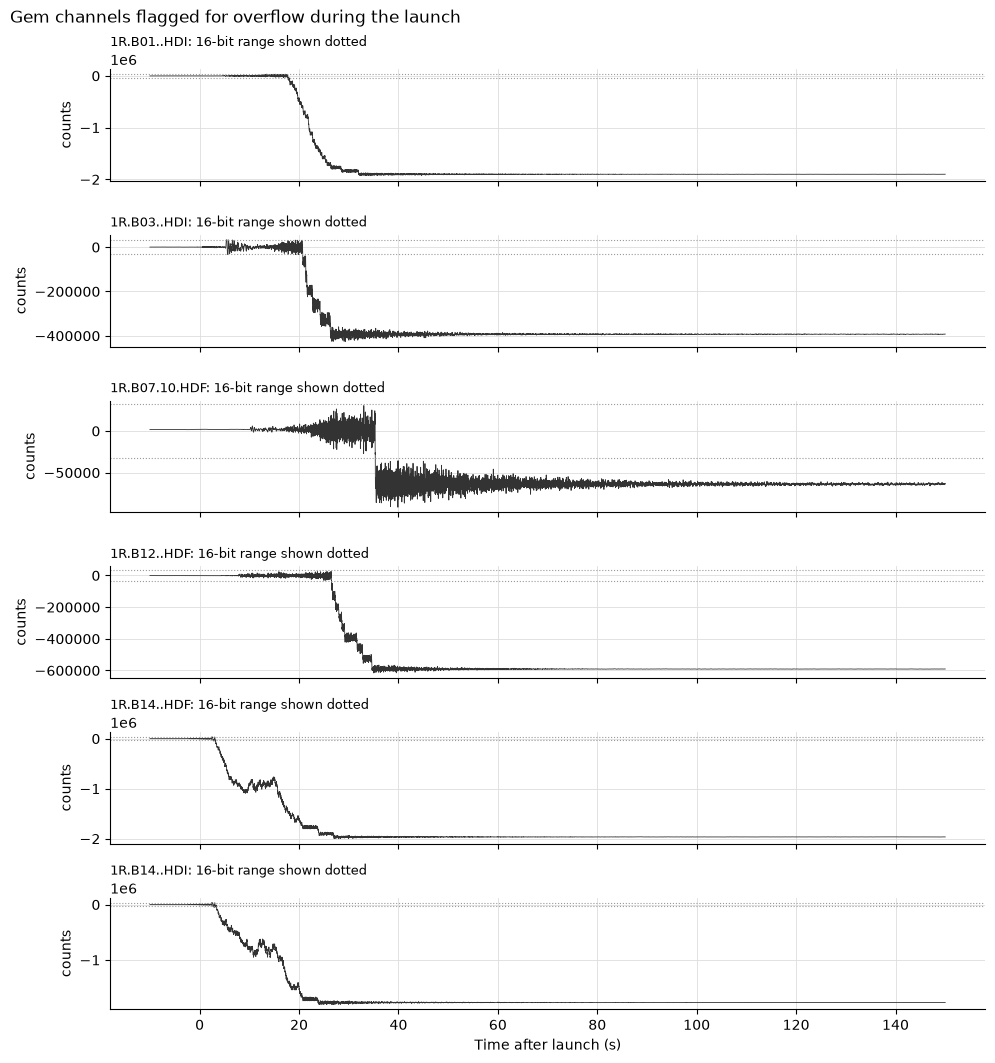

In [3]:
bad = [tr for tr in st_raw if tr.id in BAD]
fig, axes = plt.subplots(len(bad), 1, figsize=(10, 1.8 * len(bad)), sharex=True, squeeze=False)
for ax, tr in zip(axes[:, 0], sorted(bad, key=lambda t: t.id)):
    s = tr.slice(L - 10, L + 150)
    ax.plot(s.times() - 10, s.data, color='#333333', lw=0.6)
    for r in (32767, -32768):
        ax.axhline(r, color='#999999', lw=0.8, ls=':')
    ax.set_ylabel('counts')
    ax.set_title(f'{tr.id}: 16-bit range shown dotted', fontsize=9, loc='left')
axes[-1, 0].set_xlabel('Time after launch (s)')
fig.suptitle('Gem channels flagged for overflow during the launch', x=0.01, ha='left')
fig.tight_layout()
fig.savefig(OUT / 'enclosure_raw_overflow.png', dpi=200)

## 2. Instrument correction to pressure (as in notebook 25)

In [4]:
st = st_raw.copy()
st.detrend('demean')
st.filter('highpass', freq=0.05)
for i, tr in enumerate(st):
    st[i] = gemlog.deconvolve_gem_response(tr, gain='high')
print(st)

19 Trace(s) in Stream:
1R.B01..HDI   | 2026-04-01T22:05:12.000000Z - 2026-04-01T23:20:12.000000Z | 100.0 Hz, 450001 samples
1R.B03..HDI   | 2026-04-01T22:05:12.000000Z - 2026-04-01T23:20:12.000000Z | 100.0 Hz, 450001 samples
1R.B07..HDF   | 2026-04-01T22:05:12.000000Z - 2026-04-01T23:20:12.000000Z | 100.0 Hz, 450001 samples
1R.B07.10.HDF | 2026-04-01T22:05:12.000000Z - 2026-04-01T23:20:12.000000Z | 100.0 Hz, 450001 samples
1R.B12..HDF   | 2026-04-01T22:05:12.000000Z - 2026-04-01T23:20:12.000000Z | 100.0 Hz, 450001 samples
1R.B14..HDF   | 2026-04-01T22:05:12.000000Z - 2026-04-01T23:20:12.000000Z | 100.0 Hz, 450001 samples
1R.B14..HDI   | 2026-04-01T22:05:12.000000Z - 2026-04-01T23:20:12.000000Z | 100.0 Hz, 450001 samples
1R.B20..HDF   | 2026-04-01T22:05:12.000000Z - 2026-04-01T23:20:12.000000Z | 100.0 Hz, 450001 samples
1R.B20.10.HDI | 2026-04-01T22:05:12.000000Z - 2026-04-01T23:20:12.000000Z | 100.0 Hz, 450001 samples
1R.B20S..HDF  | 2026-04-01T22:05:12.000000Z - 2026-04-01T23:20:12.00

## 3. Pairs

Tote pairs (`HDI` vs `HDF`) and free-field controls (`HDF` vs `HDF`). Gem 363 (`1R.UNK..HD1`) was 8 m
from B20 according to its GPS log (notebook 10) and is compared with B20 HDF as an exploratory pair.

In [5]:
PAIRS = [  # (reference A, comparison B, kind)
    ('1R.B14..HDF', '1R.B14..HDI', 'tote'),
    ('1R.B20..HDF', '1R.B20.10.HDI', 'tote'),
    ('1R.B24..HDF', '1R.B24..HDI', 'tote'),
    ('1R.B29..HDF', '1R.B29..HDI', 'tote'),
    ('1R.B03..HDF', '1R.B03..HDI', 'tote'),
    ('1R.B07..HDF', '1R.B07.10.HDF', 'control'),
    ('1R.B20..HDF', '1R.B20W..HDF', 'control'),
    ('1R.B20..HDF', '1R.B20S..HDF', 'control'),
    ('1R.B20..HDF', '1R.UNK..HD1', 'exploratory'),
]

def get(sid):
    s = st.select(id=sid)
    return s[0] if len(s) else None

def common(a, b, window):
    x, y = a.slice(*window).data, b.slice(*window).data
    n = min(len(x), len(y))
    return x[:n].astype(float), y[:n].astype(float)

def compare(a, b):
    fs = a.stats.sampling_rate
    xs, ys = common(a, b, SIGNAL)
    xn, yn = common(a, b, NOISE)
    lag, cc = xcorr_max(correlate(xs, ys, int(MAXLAG_S * fs)))
    f, pxs = welch(xs, fs, nperseg=NPERSEG); _, pys = welch(ys, fs, nperseg=NPERSEG)
    _, pxn = welch(xn, fs, nperseg=NPERSEG); _, pyn = welch(yn, fs, nperseg=NPERSEG)
    _, coh = coherence(xs, ys, fs, nperseg=NPERSEG)
    band = (f >= BAND[0]) & (f <= BAND[1])
    metrics = dict(
        peak_A_Pa=np.abs(xs).max(), peak_B_Pa=np.abs(ys).max(),
        peak_ratio=np.abs(ys).max() / np.abs(xs).max(),
        rms_ratio=ys.std() / xs.std(),
        lag_s=lag / fs,   # ObsPy xcorr_max shift of correlate(A, B), s
        xcorr=cc,
        psd_ratio_signal=np.median(pys[band] / pxs[band]),
        coherence_signal=np.median(coh[band]),
        noise_rms_A_Pa=xn.std(), noise_rms_B_Pa=yn.std(),
        noise_rms_ratio=yn.std() / xn.std(),
        psd_ratio_noise=np.median(pyn[band] / pxn[band]),
    )
    spectra = dict(f=f, pxs=pxs, pys=pys, pxn=pxn, pyn=pyn, coh=coh)
    return metrics, spectra

rows, spectra = [], {}
for a_id, b_id, kind in PAIRS:
    a, b = get(a_id), get(b_id)
    row = dict(A=a_id, B=b_id, kind=kind)
    if a is None or b is None:
        row['status'] = 'missing: ' + ', '.join(s for s, t in ((a_id, a), (b_id, b)) if t is None)
    elif {a_id, b_id} & BAD:
        row['status'] = 'overflow: ' + ', '.join(sorted({a_id, b_id} & BAD))
    else:
        m, spec = compare(a, b)
        row.update(m, status='ok')
        spectra[(a_id, b_id)] = spec
    rows.append(row)

metrics = pd.DataFrame(rows)
metrics.to_csv(OUT / 'enclosure_comparison_metrics.csv', index=False)
with pd.option_context('display.float_format', '{:.3g}'.format, 'display.width', 200):
    display(metrics)

,A,B,kind,status,peak_A_Pa,peak_B_Pa,peak_ratio,rms_ratio,lag_s,xcorr,psd_ratio_signal,coherence_signal,noise_rms_A_Pa,noise_rms_B_Pa,noise_rms_ratio,psd_ratio_noise
0,1R.B14..HDF,1R.B14..HDI,tote,"overflow: 1R.B14..HDF, 1R.B14..HDI",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1R.B20..HDF,1R.B20.10.HDI,tote,ok,44,46.1,1.05,0.991,0,0.954,1.11,0.998,0.347,0.499,1.44,1.23
2,1R.B24..HDF,1R.B24..HDI,tote,ok,81.2,87.3,1.08,1.04,0,0.975,1.02,0.998,0.572,0.607,1.06,0.743
3,1R.B29..HDF,1R.B29..HDI,tote,ok,100,93.6,0.936,0.958,0,0.976,0.976,0.999,0.561,0.554,0.987,0.331
4,1R.B03..HDF,1R.B03..HDI,tote,missing: 1R.B03..HDF,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,1R.B07..HDF,1R.B07.10.HDF,control,overflow: 1R.B07.10.HDF,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,1R.B20..HDF,1R.B20W..HDF,control,ok,44,44.9,1.02,0.971,0.07,0.518,0.988,0.416,0.347,0.495,1.43,42.1
7,1R.B20..HDF,1R.B20S..HDF,control,ok,44,41.5,0.943,0.953,-0.07,0.7,0.903,0.632,0.347,0.403,1.16,1.58
8,1R.B20..HDF,1R.UNK..HD1,exploratory,ok,44,45.2,1.03,0.992,-0.02,0.857,0.984,0.978,0.347,0.356,1.03,0.603


## 4. Per-pair figures: waveforms, spectra, ratio, coherence

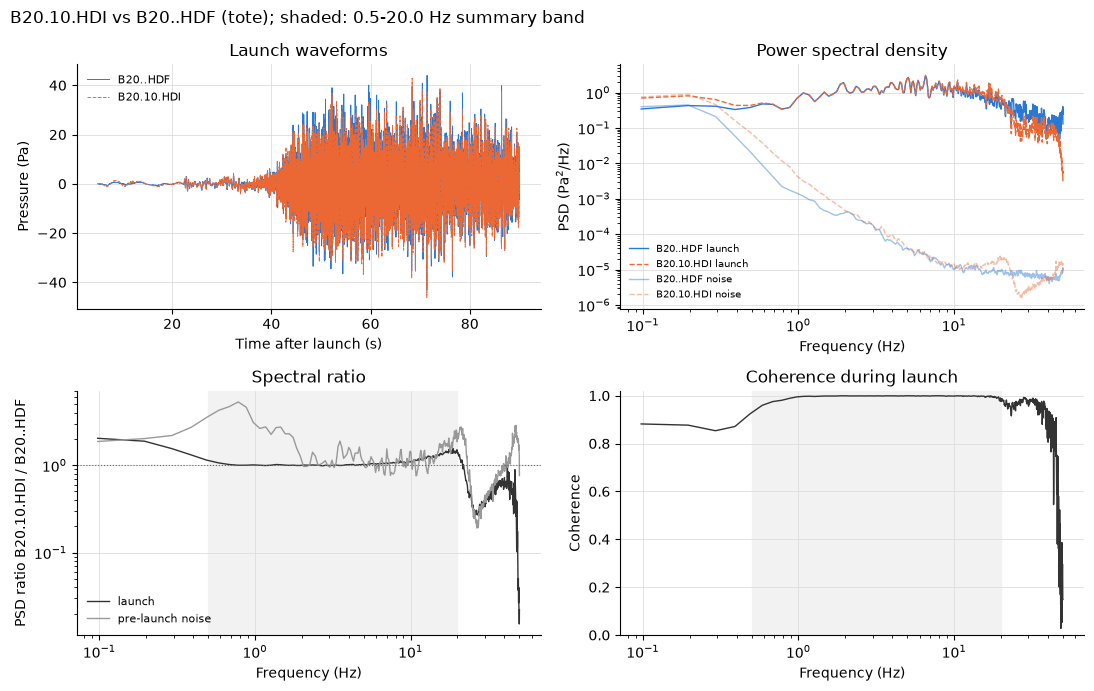

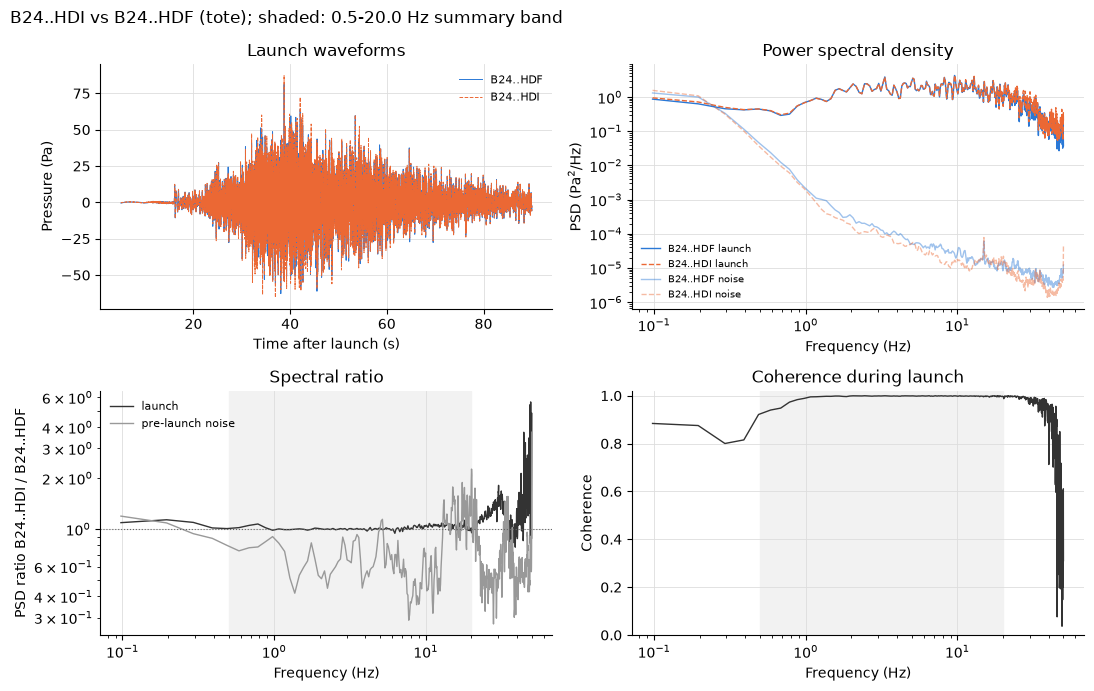

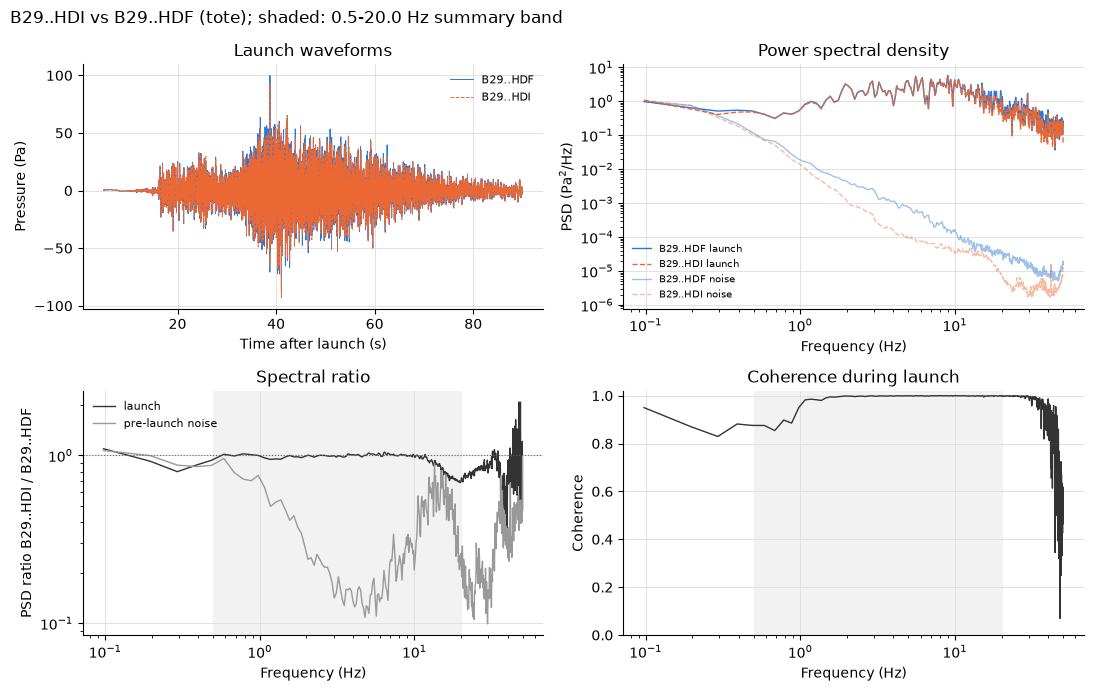

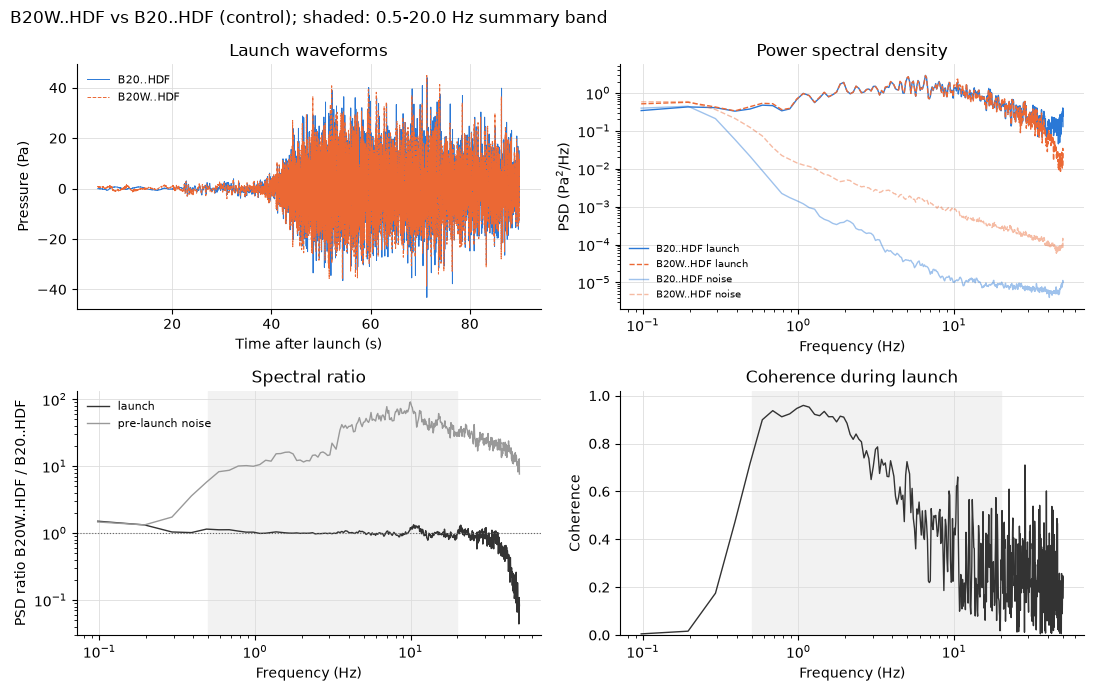

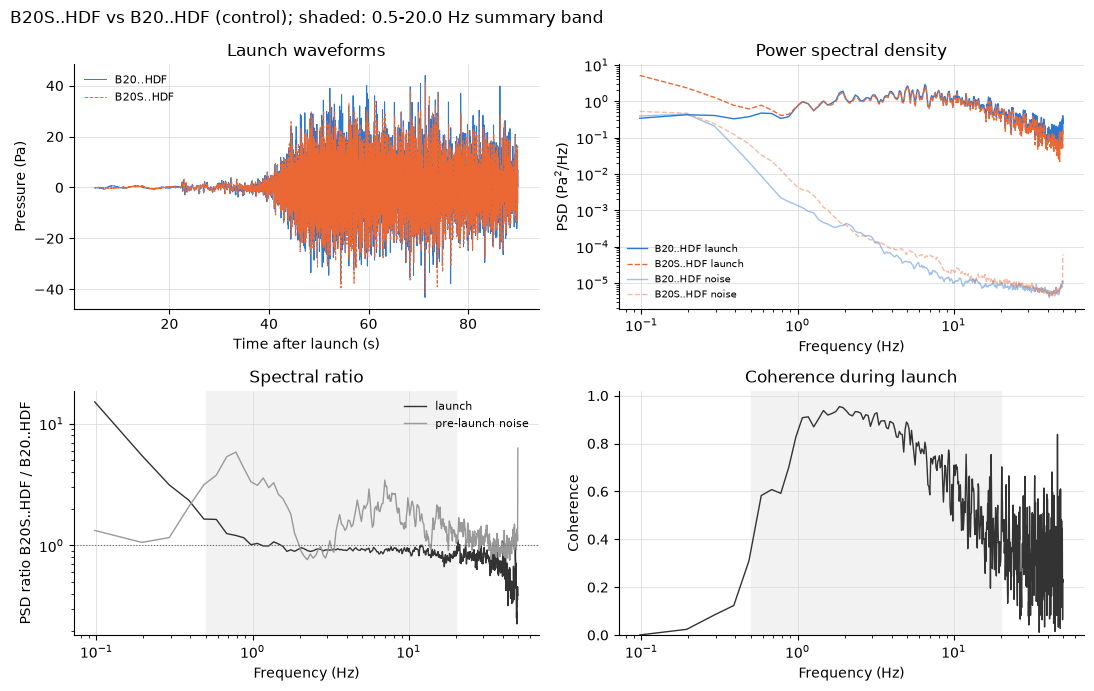

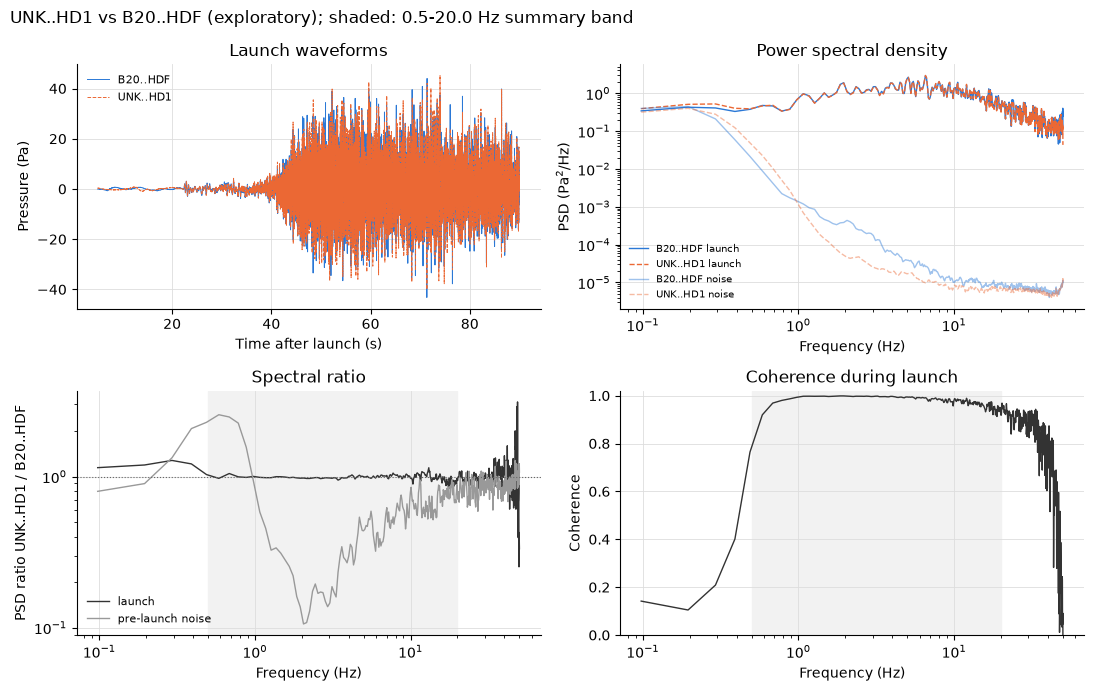

In [6]:
def label(sid):
    return sid.replace('1R.', '')

def plot_pair(a_id, b_id, kind, spec):
    a, b = get(a_id), get(b_id)
    sb = STYLE['HDI'] if b_id.endswith('HDI') else STYLE['B']
    fig, ax = plt.subplots(2, 2, figsize=(11, 7))
    for tr, sty in ((a, STYLE['HDF']), (b, sb)):
        s = tr.slice(L + 5, L + 90)
        ax[0, 0].plot(s.times() + 5, s.data, label=label(tr.id), lw=0.7, **sty)
    ax[0, 0].set(xlabel='Time after launch (s)', ylabel='Pressure (Pa)', title='Launch waveforms')
    ax[0, 0].legend(frameon=False, fontsize=8)
    f = spec['f']; band = (f >= 0.05)
    for key, tr, sty in (('pxs', a, STYLE['HDF']), ('pys', b, sb)):
        ax[0, 1].loglog(f[band], spec[key][band], label=f'{label(tr.id)} launch', **sty)
    for key, tr, sty in (('pxn', a, STYLE['HDF']), ('pyn', b, sb)):
        ax[0, 1].loglog(f[band], spec[key][band], label=f'{label(tr.id)} noise', alpha=0.45, **sty)
    ax[0, 1].set(xlabel='Frequency (Hz)', ylabel='PSD (Pa$^2$/Hz)', title='Power spectral density')
    ax[0, 1].legend(frameon=False, fontsize=7)
    ax[1, 0].semilogx(f[band], spec['pys'][band] / spec['pxs'][band], color='#333333', label='launch')
    ax[1, 0].semilogx(f[band], spec['pyn'][band] / spec['pxn'][band], color='#999999', label='pre-launch noise')
    ax[1, 0].axhline(1, color='#666666', lw=0.8, ls=':')
    ax[1, 0].set_yscale('log')
    ax[1, 0].axvspan(*BAND, color='#f2f2f2', zorder=0)
    ax[1, 0].set(xlabel='Frequency (Hz)', ylabel=f'PSD ratio {label(b_id)} / {label(a_id)}', title='Spectral ratio')
    ax[1, 0].legend(frameon=False, fontsize=8)
    ax[1, 1].semilogx(f[band], spec['coh'][band], color='#333333')
    ax[1, 1].axvspan(*BAND, color='#f2f2f2', zorder=0)
    ax[1, 1].set(xlabel='Frequency (Hz)', ylabel='Coherence', ylim=(0, 1.02), title='Coherence during launch')
    fig.suptitle(f'{label(b_id)} vs {label(a_id)} ({kind}); shaded: {BAND[0]}-{BAND[1]} Hz summary band',
                 x=0.01, ha='left')
    fig.tight_layout()
    name = f"enclosure_{label(a_id).replace('.', '_')}_vs_{label(b_id).replace('.', '_')}.png"
    fig.savefig(OUT / name, dpi=200)
    return fig

for (a_id, b_id), spec in spectra.items():
    kind = metrics.set_index(['A', 'B']).loc[(a_id, b_id), 'kind']
    plot_pair(a_id, b_id, kind, spec)
    plt.show()

## 5. Summary

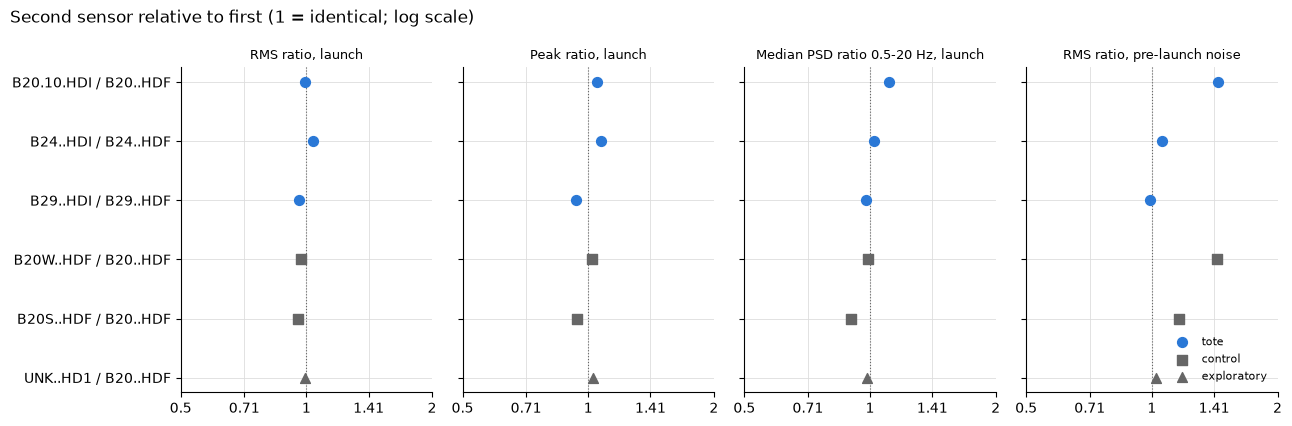

In [7]:
from matplotlib.ticker import FixedLocator, NullLocator, FuncFormatter

ok = metrics[metrics.status == 'ok'].copy()
ok['pair'] = ok['B'].map(label) + ' / ' + ok['A'].map(label)
cols = [('rms_ratio', 'RMS ratio, launch'), ('peak_ratio', 'Peak ratio, launch'),
        ('psd_ratio_signal', f'Median PSD ratio {BAND[0]:g}-{BAND[1]:g} Hz, launch'),
        ('noise_rms_ratio', 'RMS ratio, pre-launch noise')]
style = {'tote': dict(marker='o', color='#2a78d6'), 'control': dict(marker='s', color='#666666'),
         'exploratory': dict(marker='^', color='#666666')}
TICKS = [0.5, 0.71, 1, 1.41, 2]
fig, axes = plt.subplots(1, len(cols), figsize=(13, 0.45 * len(ok) + 1.6), sharey=True)
y = np.arange(len(ok))
for ax, (col, title) in zip(axes, cols):
    for kind in ('tote', 'control', 'exploratory'):
        m = (ok['kind'] == kind).to_numpy()
        if m.any():
            ax.scatter(ok[col][m], y[m], s=50, zorder=3, label=kind, **style[kind])
    ax.axvline(1, color='#666666', lw=0.8, ls=':')
    ax.set_xscale('log'); ax.set_xlim(0.5, 2)
    ax.xaxis.set_major_locator(FixedLocator(TICKS)); ax.xaxis.set_minor_locator(NullLocator())
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}'))
    ax.set_title(title, fontsize=9)
axes[0].set_yticks(y, ok['pair']); axes[0].invert_yaxis()
axes[-1].legend(frameon=False, fontsize=8, loc='lower right')
fig.suptitle('Second sensor relative to first (1 = identical; log scale)', x=0.01, ha='left')
fig.tight_layout()
fig.savefig(OUT / 'enclosure_summary.png', dpi=200)

In [8]:
print('Excluded pairs:')
print(metrics.loc[metrics.status != 'ok', ['A', 'B', 'status']].to_string(index=False))
tote = ok[ok.kind == 'tote']
print(f"\nValid tote pairs: {', '.join(tote['pair'])}")
for col in ('rms_ratio', 'peak_ratio', 'psd_ratio_signal', 'coherence_signal', 'xcorr', 'noise_rms_ratio'):
    print(f'  {col:18s} {tote[col].min():.2f} - {tote[col].max():.2f}')

Excluded pairs:
          A             B                             status
1R.B14..HDF   1R.B14..HDI overflow: 1R.B14..HDF, 1R.B14..HDI
1R.B03..HDF   1R.B03..HDI               missing: 1R.B03..HDF
1R.B07..HDF 1R.B07.10.HDF            overflow: 1R.B07.10.HDF

Valid tote pairs: B20.10.HDI / B20..HDF, B24..HDI / B24..HDF, B29..HDI / B29..HDF
  rms_ratio          0.96 - 1.04
  peak_ratio         0.94 - 1.08
  psd_ratio_signal   0.98 - 1.11
  coherence_signal   1.00 - 1.00
  xcorr              0.95 - 0.98
  noise_rms_ratio    0.99 - 1.44


## 6. Dependence on the upper frequency limit

The summary above uses 0.5–20 Hz, below the Gem's nominal upper corner (~27 Hz). Both Gems in a pair are
the same model, so their ratio is insensitive to the shared response, and an enclosure is most likely to act
at the higher frequencies (wall transmission loss, cavity resonance). Two views, up to 45 Hz (0.9 × Nyquist):

* **cumulative**: median coherence and PSD ratio over 0.5 Hz to an upper corner *f_c* = 20, 25, …, 45 Hz,
  and peak/RMS ratios after band-passing both records to 0.5 Hz–*f_c*;
* **banded**: median PSD ratio and coherence in separate bands (0.5–5, 5–10, 10–20, 20–30, 30–40, 40–45 Hz).

Cumulative medians are dominated by the low frequencies, where most launch energy lies; the banded view shows
where a difference actually occurs. Coherence is insensitive to the travel-time lag between separated sensors,
unlike zero-lag correlation.

Outputs: `enclosure_vs_upper_corner.csv`, `enclosure_bands.csv`, `enclosure_vs_frequency.png`.

In [ ]:
FC = [20, 25, 30, 35, 40, 45]
FBANDS = [(0.5, 5), (5, 10), (10, 20), (20, 30), (30, 40), (40, 45)]
cum, banded = [], []
for a_id, b_id, kind in PAIRS:
    a, b = get(a_id), get(b_id)
    if a is None or b is None or {a_id, b_id} & BAD:
        continue
    pair = f'{label(b_id)} / {label(a_id)}'
    for win_name, win in (('launch', SIGNAL), ('noise', NOISE)):
        x, y = common(a, b, win)
        f, px = welch(x, 100, nperseg=NPERSEG); _, py = welch(y, 100, nperseg=NPERSEG)
        _, coh = coherence(x, y, 100, nperseg=NPERSEG)
        for lo, hi in FBANDS:
            m = (f >= lo) & (f < hi)
            banded.append(dict(pair=pair, kind=kind, window=win_name, band=f'{lo:g}-{hi:g}', f_lo=lo, f_hi=hi,
                               psd_ratio=np.median(py[m] / px[m]), coherence=np.median(coh[m])))
        if win_name != 'launch':
            continue
        for fc in FC:
            m = (f >= 0.5) & (f <= fc)
            aa, bb = a.copy(), b.copy()
            for t in (aa, bb):
                t.filter('bandpass', freqmin=0.5, freqmax=fc, corners=4, zerophase=True)
            xs, ys = common(aa, bb, SIGNAL)
            cum.append(dict(pair=pair, kind=kind, fc=fc, coherence=np.median(coh[m]),
                            coherence_p10=np.percentile(coh[m], 10), psd_ratio=np.median(py[m] / px[m]),
                            rms_ratio=ys.std() / xs.std(), peak_ratio=np.abs(ys).max() / np.abs(xs).max()))
cum, banded = pd.DataFrame(cum), pd.DataFrame(banded)
cum.to_csv(OUT / 'enclosure_vs_upper_corner.csv', index=False)
banded.to_csv(OUT / 'enclosure_bands.csv', index=False)
order = list(dict.fromkeys(cum.pair))
with pd.option_context('display.float_format', '{:.3f}'.format, 'display.width', 200):
    for col in ('coherence', 'coherence_p10', 'psd_ratio', 'rms_ratio', 'peak_ratio'):
        print(col); display(cum.pivot(index='pair', columns='fc', values=col).loc[order])
    bl = banded[banded.window == 'launch']
    print('banded PSD ratio (dB), launch')
    display((10 * np.log10(bl.pivot(index='pair', columns='f_lo', values='psd_ratio'))).loc[order])

In [ ]:
COL = {'tote': '#2a78d6', 'control': '#666666', 'exploratory': '#666666'}
LS = ['-', '--', ':']
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
k = {'tote': 0, 'control': 0, 'exploratory': 0}
for pair in order:
    g = cum[cum.pair == pair]; kind = g.kind.iloc[0]
    sty = dict(color=COL[kind], ls=LS[k[kind] % 3], marker='o' if kind == 'tote' else ('s' if kind == 'control' else '^'), ms=4)
    k[kind] += 1
    ax[0].plot(g.fc, g.coherence, label=pair, **sty)
    b = banded[(banded.pair == pair) & (banded.window == 'launch')]
    mid = (b.f_lo + b.f_hi) / 2
    ax[1].plot(mid, 10 * np.log10(b.psd_ratio), **sty)
    ax[2].plot(mid, b.coherence, **sty)
ax[0].set(xlabel='Upper corner $f_c$ (Hz)', ylabel='Median coherence, 0.5 Hz to $f_c$', ylim=(0, 1.02),
          title='Cumulative band, launch')
ax[1].axhline(0, color='#999999', lw=0.8)
ax[1].set(xlabel='Band centre (Hz)', ylabel='Median PSD ratio (dB), second / first', title='Separate bands, launch')
ax[2].set(xlabel='Band centre (Hz)', ylabel='Median coherence', ylim=(0, 1.02), title='Separate bands, launch')
ax[0].legend(frameon=False, fontsize=7, loc='lower left')
for a in ax:
    a.grid(True, color='#dddddd', lw=0.6)
fig.suptitle('Tote (blue) and free-field control (gray) pairs up to 45 Hz', x=0.01, ha='left')
fig.tight_layout()
fig.savefig(OUT / 'enclosure_vs_frequency.png', dpi=200)